# THỰC HÀNH XÂY DỰNG MÔ HÌNH CLASSIFICATION VỚI DỮ LIỆU BẢNG

### Bài toán
Xây dựng mô hình **phân loại nhị phân** để nhận diện mẫu thuộc lớp **malignant** từ bộ dữ liệu Breast Cancer Wisconsin của `scikit-learn`.

Bài này đi vào quy trình xây dựng và đánh giá mô hình classification khi dữ liệu bị **class imbalance**.

### Mục tiêu h
- Nhận biết một bài toán **binary classification**.
- Phân tích mức độ **mất cân bằng lớp**.
- Hiểu vì sao **Accuracy có thể gây hiểu nhầm** khi dữ liệu imbalance.
- Chia dữ liệu bằng `train_test_split(..., stratify=y)`.
- Hiểu và sử dụng **StandardScaler** đúng cách.
- Hiểu nguyên lý **K-Fold Cross Validation**.
- Phân biệt `KFold` và `StratifiedKFold`.
- Đánh giá mô hình bằng Accuracy, Precision, Recall, F1-score, ROC-AUC và PR-AUC.
- Áp dụng:
  - Random Over-Sampling;
  - Random Under-Sampling;
  - SMOTE.
- Kết hợp chuẩn hóa + sampling + model bằng **Pipeline** để tránh **data leakage**.
- So sánh các phương án bằng Cross Validation trước khi đánh giá trên tập test.

# PHẦN 1. CHUẨN BỊ MÔI TRƯỜNG

## Bước 1. Cài đặt và import thư viện

Các thư viện chính:

- `numpy`, `pandas`: xử lý dữ liệu.
- `matplotlib`: trực quan hóa.
- `scikit-learn`: dataset, preprocessing, model, cross validation và metrics.
- `imbalanced-learn`: các kỹ thuật sampling và pipeline dành cho dữ liệu mất cân bằng.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    cross_validate
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    make_scorer
)

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-n868qhvf because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## Bước 2. Nạp dữ liệu Breast Cancer Wisconsin

Bộ dữ liệu gồm:

- **569 mẫu** trong dữ liệu gốc.
- **30 đặc trưng số**.
- Hai lớp:
  - `malignant`: ác tính;
  - `benign`: lành tính.

Trong `scikit-learn`, nhãn gốc là:

- `0 = malignant`
- `1 = benign`

Để thuận tiện cho bài toán mất cân bằng, ta sẽ đổi lại:

- **1 = malignant** → lớp cần phát hiện;
- **0 = benign**.


In [ ]:
cancer = load_breast_cancer(as_frame=True)

X_full = cancer.data.copy()

y_full = (cancer.target == 0).astype(int)

df_full = X_full.copy()
df_full["target"] = y_full

print("Kích thước dữ liệu gốc:", df_full.shape)
display(df_full.head())

Kích thước dữ liệu gốc: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## (Chỉ cho bài thực hành) Tạo phiên bản dữ liệu mất cân bằng rõ hơn cho bài thực hành

Tạo tình huống mất cân bằng dữ liệu cho bài toán

- Giữ toàn bộ mẫu `benign`.
- Chỉ lấy ngẫu nhiên **60 mẫu malignant**.

In [ ]:
benign_df = df_full[df_full["target"] == 0]
malignant_df = df_full[df_full["target"] == 1].sample(
    n=60,
    random_state=RANDOM_STATE
)

df = pd.concat([benign_df, malignant_df], axis=0)
df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("Kích thước dữ liệu thực hành:", df.shape)
display(df.head())

Kích thước dữ liệu thực hành: (417, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,14.26,18.17,91.22,633.1,0.06576,0.05220,0.02475,0.01374,0.1635,0.05586,0.2300,0.6690,1.661,20.56,0.003169,0.013770,0.01079,0.005243,0.01103,0.001957,16.220,25.26,105.80,819.7,0.09445,0.21670,0.15650,0.07530,0.2636,0.07676,0
1,19.53,32.47,128.00,1223.0,0.08420,0.11300,0.11450,0.06637,0.1428,0.05313,0.7392,1.3210,4.722,109.90,0.005539,0.026440,0.02664,0.010780,0.01332,0.002256,27.900,45.41,180.20,2477.0,0.14080,0.40970,0.39950,0.16250,0.2713,0.07568,1
2,15.34,14.26,102.50,704.4,0.10730,0.21350,0.20770,0.09756,0.2521,0.07032,0.4388,0.7096,3.384,44.91,0.006789,0.053280,0.06446,0.022520,0.03672,0.004394,18.070,19.08,125.10,980.9,0.13900,0.59540,0.63050,0.23930,0.4667,0.09946,1
3,9.72,18.22,60.73,288.1,0.06950,0.02344,0.00000,0.00000,0.1653,0.06447,0.3539,4.8850,2.230,21.69,0.001713,0.006736,0.00000,0.000000,0.03799,0.001688,9.968,20.83,62.25,303.8,0.07117,0.02729,0.00000,0.00000,0.1909,0.06559,0
4,11.15,13.08,70.87,381.9,0.09754,0.05113,0.01982,0.01786,0.1830,0.06105,0.2251,0.7815,1.429,15.48,0.009019,0.008985,0.01196,0.008232,0.02388,0.001619,11.990,16.30,76.25,440.8,0.13410,0.08971,0.07116,0.05506,0.2859,0.06772,0


# PHẦN 2. EDA

## Bước 3. Kiểm tra cấu trúc dữ liệu

Rút gọn EDA, chỉ tập trung vào những câu hỏi trực tiếp ảnh hưởng đến classification:

1. Có bao nhiêu mẫu và bao nhiêu feature?
2. Có missing value không?
3. Có dữ liệu trùng lặp không?
4. Tỷ lệ hai lớp có cân bằng không?
5. Các feature có khác nhau nhiều về thang đo không?

In [ ]:
print("Shape:", df.shape)
print("\nSố giá trị thiếu:")
print(df.isna().sum().sum())

print("\nSố dòng trùng lặp:")
print(df.duplicated().sum())

print("\nKiểu dữ liệu:")
display(df.dtypes.value_counts())

Shape: (417, 31)

Số giá trị thiếu:
0

Số dòng trùng lặp:
0

Kiểu dữ liệu:


float64    30
int64       1
Name: count, dtype: int64

## Bước 4. Phân tích phân bố lớp

Đây là bước đặc biệt quan trọng với classification. Nếu một lớp xuất hiện nhiều hơn rất nhiều so với lớp còn lại, mô hình có thể đạt Accuracy cao bằng cách ưu tiên dự đoán lớp đa số.

In [ ]:
class_count = df["target"].value_counts().sort_index()
class_percent = df["target"].value_counts(normalize=True).sort_index() * 100

class_distribution = pd.DataFrame({
    "Số mẫu": class_count,
    "Tỷ lệ (%)": class_percent.round(2)
})
class_distribution.index = ["Benign (0)", "Malignant (1)"]

display(class_distribution)

,Số mẫu,Tỷ lệ (%)
Benign (0),357,85.61
Malignant (1),60,14.39


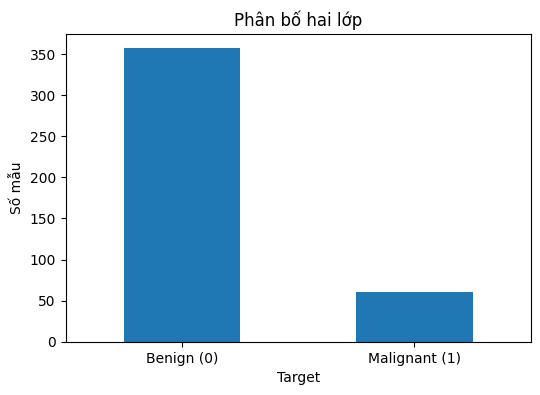

In [ ]:
plt.figure(figsize=(6, 4))
class_count.plot(kind="bar")
plt.title("Phân bố hai lớp")
plt.xlabel("Target")
plt.ylabel("Số mẫu")
plt.xticks(
    ticks=[0, 1],
    labels=["Benign (0)", "Malignant (1)"],
    rotation=0
)
plt.show()

### Nhận xét cần rút ra

Bước này giúp chúng ta biết được:

- Lớp nào là **majority class**?
- Lớp nào là **minority class**?
- Nếu mô hình luôn dự đoán `Benign`, Accuracy có thể đạt khoảng bao nhiêu?
- Accuracy cao trong trường hợp đó có đồng nghĩa mô hình tốt không?

Đây là lý do ta cần xem thêm **Recall, Precision, F1 và PR-AUC**.

## Bước 5. Kiểm tra thang đo của các feature

Các feature trong dữ liệu có đơn vị và độ lớn khác nhau.

Ví dụ:

- một feature có thể có giá trị khoảng `0.1`;
- feature khác có thể có giá trị hàng trăm hoặc hàng nghìn.

Điều này đặc biệt quan trọng với các thuật toán nhạy với scale, đồng thời ảnh hưởng đến regularization của Logistic Regression.

In [ ]:
feature_scale = pd.DataFrame({
    "mean": df.drop(columns="target").mean(),
    "std": df.drop(columns="target").std(),
    "min": df.drop(columns="target").min(),
    "max": df.drop(columns="target").max()
}).sort_values("std", ascending=False)

display(feature_scale.head(10))

,mean,std,min,max
worst area,694.379376,422.448118,185.200,3143.00
mean area,542.766187,260.390089,143.500,1747.00
worst perimeter,95.476595,26.401634,50.410,211.50
area error,28.184887,25.059015,6.802,224.10
mean perimeter,83.851966,19.256076,43.790,155.10
worst texture,24.404436,5.865735,12.020,45.41
mean texture,18.479065,4.184295,9.710,33.81
worst radius,14.587096,3.806504,7.930,30.79
mean radius,12.973859,2.822081,6.981,23.51
perimeter error,2.315299,1.319541,0.757,10.05


Các feature có thang đo rất khác nhau. Ví dụ:

- worst area có độ lệch chuẩn khoảng 422.45 và giá trị lớn nhất 3143.

- mean area có độ lệch chuẩn khoảng 260.39.

- mean radius chỉ có độ lệch chuẩn khoảng 2.82.

- perimeter error có độ lệch chuẩn khoảng 1.32.

Cần phải áp dụng StandardScaler, đặc biệt với Logistic Regression có regularization và với SMOTE là phương pháp phụ thuộc khoảng cách giữa các điểm dữ liệu.

# PHẦN 3. TRAIN/TEST SPLIT

## Bước 6. Tách `X` và `y`

- `X`: các feature đầu vào.
- `y`: nhãn cần dự đoán.

Lưu ý: Không được thực hiện sampling hay chuẩn hóa trước bước chia dữ liệu.

In [ ]:
X = df.drop(columns="target")
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (417, 30)
y shape: (417,)


## Bước 7. Train/Test Split với `stratify=y`

Với dữ liệu mất cân bằng, nên sử dụng:

```python
stratify=y
```

để tỷ lệ các lớp trong train và test gần giống tỷ lệ trong dữ liệu ban đầu.

Tập **test được giữ nguyên và không dùng để lựa chọn mô hình**. Các phương án sẽ được so sánh bằng Cross Validation trên tập train.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (333, 30)
Test : (84, 30)


In [ ]:
def show_class_ratio(y_data, name):
    count = y_data.value_counts().sort_index()
    ratio = y_data.value_counts(normalize=True).sort_index() * 100

    result = pd.DataFrame({
        "count": count,
        "percent": ratio.round(2)
    })
    result.index = ["Benign (0)", "Malignant (1)"]

    print(name)
    display(result)

show_class_ratio(y_train, "TRAIN")
show_class_ratio(y_test, "TEST")

TRAIN


,count,percent
Benign (0),285,85.59
Malignant (1),48,14.41


TEST


,count,percent
Benign (0),72,85.71
Malignant (1),12,14.29



### Lưu ý  
Không được phép:

- fit `StandardScaler` trên toàn bộ dữ liệu;
- sampling toàn bộ dữ liệu;
- tạo dữ liệu synthetic trước khi chia train/test.

Nếu làm như vậy, thông tin từ test có thể ảnh hưởng đến quá trình training → **data leakage**.

# PHẦN 4. Evaluation

## Bước 8. Tạo bộ metric cho Classification

Các chỉ số đánh giá

- **Accuracy**: tỷ lệ dự đoán đúng tổng thể.
- **Precision**: trong các mẫu dự đoán malignant, bao nhiêu mẫu thật sự malignant.
- **Recall**: trong các mẫu malignant thật, mô hình phát hiện được bao nhiêu.
- **F1-score**: trung bình điều hòa giữa Precision và Recall.
- **ROC-AUC**: khả năng phân biệt hai lớp trên nhiều threshold.
- **PR-AUC / Average Precision**: đặc biệt hữu ích khi lớp dương là minority class.

In [ ]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

## Bước 9. Train một baseline chỉ dự đoán lớp đa số

`DummyClassifier(strategy="most_frequent")` không học quan hệ giữa feature và target. Nó chỉ luôn dự đoán lớp xuất hiện nhiều nhất. Nếu mô hình này vẫn có Accuracy tương đối cao, ta thấy ngay vì sao **Accuracy đơn lẻ có thể gây hiểu nhầm**.

In [ ]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

dummy = DummyClassifier(strategy="most_frequent")

dummy_cv = cross_validate(
    dummy,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring
)

dummy_summary = {
    metric: dummy_cv[f"test_{metric}"].mean()
    for metric in scoring.keys()
}

display(pd.Series(dummy_summary, name="Dummy Classifier").round(4))

accuracy     0.8559
precision    0.0000
recall       0.0000
f1           0.0000
roc_auc      0.5000
pr_auc       0.1441
Name: Dummy Classifier, dtype: float64

Accuracy khoảng 85.6% là cao, nhưng thực tế classifier không phát hiện được một mẫu Malignant nào.

Recall = 0 cho thấy toàn bộ minority class bị bỏ sót.

ROC-AUC = 0.5 cũng tương đương khả năng phân biệt ngẫu nhiên.

Một mô hình có Accuracy cao nhưng Recall gần 0 là mô hình gần như **không phát hiện được minority class**.

# PHẦN 4. CHUẨN HÓA DỮ LIỆU

## Bước 10. StandardScaler

StandardScaler biến đổi mỗi feature theo công thức:

\[
z = \frac{x - \mu}{\sigma}
\]

Sau chuẩn hóa:

- mean của feature trên tập được fit gần 0;
- standard deviation gần 1.


Logistic Regression mặc định có regularization. Nếu các feature có scale rất khác nhau, regularization có thể tác động không đồng đều lên các hệ số. Ngoài ra, các phương pháp dựa trên khoảng cách như KNN, SVM-RBF hoặc SMOTE càng nhạy với scale.

### Lưu ý 1
Không fit scaler trên toàn bộ dữ liệu

```python
scaler.fit(X)
```

trước khi Cross Validation.

Ta cần đưa scaler vào **Pipeline**:

```text
Training fold
    ↓
StandardScaler.fit()
    ↓
transform()
    ↓
Model.fit()
```

Khi sang fold khác, scaler sẽ được fit lại chỉ bằng training portion của fold đó.

In [ ]:
logreg_no_scale = LogisticRegression(
    max_iter=5000,
    random_state=RANDOM_STATE
)

logreg_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

In [ ]:
def cv_summary(model, X_data, y_data, cv):
    scores = cross_validate(
        model,
        X_data,
        y_data,
        cv=cv,
        scoring=scoring
    )

    row = {}
    for metric in scoring.keys():
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std()

    return row

scale_compare = pd.DataFrame({
    "Logistic Regression - Raw": cv_summary(
        logreg_no_scale, X_train, y_train, skf
    ),
    "Logistic Regression - StandardScaler": cv_summary(
        logreg_scaled, X_train, y_train, skf
    )
}).T

display(scale_compare.round(4))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
Logistic Regression - Raw,0.970,0.0190,0.9278,0.0988,0.8778,0.1163,0.8928,0.0670,0.9789,0.0193,0.9340,0.0550
Logistic Regression - StandardScaler,0.985,0.0164,0.9618,0.0469,0.9400,0.1200,0.9447,0.0646,0.9951,0.0098,0.9855,0.0291


Chuẩn hóa không chỉ làm thay đổi Accuracy mà còn cải thiện rõ khả năng phát hiện minority class.

### Lưu ý 2
Không nên kết luận chỉ dựa vào một metric.

Cần quan sát đồng thời:

- Recall có tăng không?
- F1 có thay đổi không?
- PR-AUC có thay đổi không?
- Standard deviation giữa các fold có lớn không?

# PHẦN 6. K-FOLD CROSS VALIDATION

## Bước 11. Ý tưởng của K-Fold Cross Validation

Với `K = 5`:

1. Chia tập train thành 5 phần.
2. Mỗi lần:
   - dùng 4 phần để train;
   - dùng 1 phần để validation.
3. Lặp lại 5 lần để mỗi phần được dùng làm validation đúng một lần.
4. Lấy trung bình metric của 5 lần.

Nếu metric trên 5 fold lần lượt là:

\[
M_1, M_2, ..., M_K
\]

thì:

\[
\bar{M} = \frac{1}{K}\sum_{i=1}^{K} M_i
\]

Ta cũng quan tâm đến **standard deviation** để xem kết quả có ổn định giữa các fold không.

KFold và StratifiedKFold khác nhau như thế nào?

### `KFold`
Chỉ chia dữ liệu thành K phần, **không đảm bảo tỷ lệ lớp**.

### `StratifiedKFold`
Cố gắng giữ tỷ lệ class trong mỗi fold gần với tỷ lệ của toàn bộ dữ liệu.

Với classification có class imbalance, `StratifiedKFold` thường là lựa chọn phù hợp hơn.

In [ ]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

stratified_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [ ]:
def get_fold_distribution(cv, X_data, y_data, cv_name):
    rows = []

    for fold, (train_idx, val_idx) in enumerate(cv.split(X_data, y_data), start=1):
        y_fold_train = y_data.iloc[train_idx]
        y_fold_val = y_data.iloc[val_idx]

        rows.append({
            "CV": cv_name,
            "Fold": fold,
            "Train malignant (%)": 100 * y_fold_train.mean(),
            "Validation malignant (%)": 100 * y_fold_val.mean(),
            "Validation size": len(val_idx)
        })

    return pd.DataFrame(rows)

dist_kfold = get_fold_distribution(
    kfold, X_train.reset_index(drop=True), y_train.reset_index(drop=True), "KFold"
)

dist_skfold = get_fold_distribution(
    stratified_kfold,
    X_train.reset_index(drop=True),
    y_train.reset_index(drop=True),
    "StratifiedKFold"
)

fold_distribution = pd.concat(
    [dist_kfold, dist_skfold],
    ignore_index=True
)

display(fold_distribution.round(2))

,CV,Fold,Train malignant (%),Validation malignant (%),Validation size
0,KFold,1,15.41,10.45,67
1,KFold,2,14.29,14.93,67
2,KFold,3,13.53,17.91,67
3,KFold,4,13.86,16.67,66
4,KFold,5,14.98,12.12,66
5,StratifiedKFold,1,14.29,14.93,67
6,StratifiedKFold,2,14.29,14.93,67
7,StratifiedKFold,3,14.29,14.93,67
8,StratifiedKFold,4,14.61,13.64,66
9,StratifiedKFold,5,14.61,13.64,66


Ở `StratifiedKFold`, tỷ lệ malignant trong validation folds thường gần nhau hơn.

Điều này giúp việc đánh giá mô hình ổn định hơn, đặc biệt khi minority class có ít mẫu.

## Bước 11. Cross Validation cho Logistic Regression

Từ đây, ta dùng `StratifiedKFold` làm mặc định.

In [ ]:
baseline_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

baseline_cv = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    cv=stratified_kfold,
    scoring=scoring
)

baseline_cv_table = pd.DataFrame({
    metric: baseline_cv[f"test_{metric}"]
    for metric in scoring.keys()
})

baseline_cv_table.index = [
    f"Fold {i}" for i in range(1, len(baseline_cv_table) + 1)
]

display(baseline_cv_table.round(4))

,accuracy,precision,recall,f1,roc_auc,pr_auc
Fold 1,1.0000,1.0000,1.0,1.0000,1.0000,1.0000
Fold 2,0.9552,1.0000,0.7,0.8235,0.9754,0.9273
Fold 3,0.9851,0.9091,1.0,0.9524,1.0000,1.0000
Fold 4,0.9848,0.9000,1.0,0.9474,1.0000,1.0000
Fold 5,1.0000,1.0000,1.0,1.0000,1.0000,1.0000


Điểm đáng chú ý là Accuracy của Fold 2 vẫn hơn 95%, nhưng Recall chỉ còn 70%. Đây một lần nữa cho thấy Accuracy có thể che giấu vấn đề ở minority class.

In [ ]:
baseline_cv_result = pd.DataFrame({
    "Mean": baseline_cv_table.mean(),
    "Std": baseline_cv_table.std()
})

display(baseline_cv_result.round(4))

,Mean,Std
accuracy,0.9850,0.0183
precision,0.9618,0.0524
recall,0.9400,0.1342
f1,0.9447,0.0722
roc_auc,0.9951,0.0110
pr_auc,0.9855,0.0325


Recall có độ lệch chuẩn lớn nhất (0.1342), nghĩa là khả năng phát hiện Malignant thay đổi nhiều hơn các metric khác giữa các fold.

Nguyên nhân có thể là do minority class chỉ có 48 mẫu trong tập train. Mỗi fold validation chỉ chứa khoảng 9–10 mẫu Malignant, do đó chỉ cần bỏ sót vài mẫu cũng làm Recall thay đổi đáng kể.

# PHẦN 7. XỬ LÝ CLASS IMBALANCE BẰNG SAMPLING

## Bước 12. Random Over-Sampling

Ý tưởng:

- Giữ nguyên majority class.
- Lấy lặp lại các mẫu minority class cho đến khi đạt tỷ lệ mong muốn.

### Ưu điểm
- Không làm mất mẫu majority.
- Đơn giản, dễ hiểu.

### Nhược điểm
- Có thể lặp lại cùng mẫu nhiều lần.
- Có nguy cơ overfitting minority class.

In [ ]:
ros = RandomOverSampler(random_state=RANDOM_STATE)

X_ros_demo, y_ros_demo = ros.fit_resample(X_train, y_train)

print("Trước Random Over-Sampling:")
print(y_train.value_counts().sort_index())

print("\nSau Random Over-Sampling:")
print(pd.Series(y_ros_demo).value_counts().sort_index())

Trước Random Over-Sampling:
target
0    285
1     48
Name: count, dtype: int64

Sau Random Over-Sampling:
target
0    285
1    285
Name: count, dtype: int64


## Bước 13. Random Under-Sampling

Ý tưởng:

- Giữ minority class.
- Loại bớt ngẫu nhiên mẫu của majority class.

### Ưu điểm
- Dataset nhỏ hơn → train nhanh hơn.
- Có thể giảm sự áp đảo của majority class.

### Nhược điểm
- Làm mất dữ liệu thật.
- Có thể bỏ đi các mẫu majority quan trọng.

In [ ]:
rus = RandomUnderSampler(random_state=RANDOM_STATE)

X_rus_demo, y_rus_demo = rus.fit_resample(X_train, y_train)

print("Trước Random Under-Sampling:")
print(y_train.value_counts().sort_index())

print("\nSau Random Under-Sampling:")
print(pd.Series(y_rus_demo).value_counts().sort_index())

Trước Random Under-Sampling:
target
0    285
1     48
Name: count, dtype: int64

Sau Random Under-Sampling:
target
0    48
1    48
Name: count, dtype: int64


## Bước 14. SMOTE

SMOTE không chỉ sao chép mẫu minority.

Nó tạo các mẫu tổng hợp mới dựa trên các mẫu minority lân cận.

Điểm cần nhớ:

- SMOTE dựa trên khoảng cách.
- Vì vậy scale của feature rất quan trọng.
- Trong quy trình đúng, nên để `StandardScaler` và `SMOTE` bên trong cùng một Pipeline.

Ta chỉ minh họa số lượng mẫu ở đây; phần huấn luyện chính thức sẽ dùng Pipeline.

In [ ]:
scaler_demo = StandardScaler()
X_train_scaled_demo = scaler_demo.fit_transform(X_train)

smote_demo = SMOTE(random_state=RANDOM_STATE)

X_smote_demo, y_smote_demo = smote_demo.fit_resample(
    X_train_scaled_demo,
    y_train
)

print("Trước SMOTE:")
print(y_train.value_counts().sort_index())

print("\nSau SMOTE:")
print(pd.Series(y_smote_demo).value_counts().sort_index())

Trước SMOTE:
target
0    285
1     48
Name: count, dtype: int64

Sau SMOTE:
target
0    285
1    285
Name: count, dtype: int64


# PHẦN 8. PIPELINE ĐÚNG CÁCH: SCALE + SAMPLE + MODEL

Tại sao sampling phải nằm trong Pipeline?

Giả sử ta sampling toàn bộ `X_train` trước rồi mới Cross Validation.

Khi đó một mẫu được tạo hoặc sao chép từ dữ liệu có thể ảnh hưởng gián tiếp đến cả training fold và validation fold.

Kết quả CV có thể **quá lạc quan**.

Quy trình đúng cho mỗi fold:

```text
Training portion của fold
        ↓
StandardScaler.fit_transform()
        ↓
Sampling.fit_resample()
        ↓
LogisticRegression.fit()
        ↓
Validation portion
        ↓
StandardScaler.transform()
        ↓
Model.predict()
```

Validation data **không được sampling**.

## Bước 15. Xây dựng các Pipeline để so sánh

Ta giữ cùng một classifier để chỉ thay đổi chiến lược xử lý imbalance:

1. Không sampling.
2. Random Over-Sampling.
3. Random Under-Sampling.
4. SMOTE.

In [ ]:
models = {
    "No Sampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random OverSampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomOverSampler(
            random_state=RANDOM_STATE
        )),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random UnderSampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomUnderSampler(
            random_state=RANDOM_STATE
        )),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "SMOTE": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(
            random_state=RANDOM_STATE
        )),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ])
}

## Bước 16. Đánh giá các phương án bằng Stratified K-Fold

Tất cả mô hình được đánh giá trên **cùng các folds** để so sánh công bằng.

In [ ]:
all_results = []

for name, model in models.items():
    result = cv_summary(
        model,
        X_train,
        y_train,
        stratified_kfold
    )
    result["model"] = name
    all_results.append(result)

cv_comparison = pd.DataFrame(all_results).set_index("model")

display(cv_comparison.round(4))

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
model,,,,,,,,,,,,
No Sampling,0.9850,0.0164,0.9618,0.0469,0.94,0.12,0.9447,0.0646,0.9951,0.0098,0.9855,0.0291
Random OverSampling,0.9850,0.0094,0.9418,0.0476,0.96,0.08,0.9472,0.0353,0.9951,0.0098,0.9855,0.0291
Random UnderSampling,0.9849,0.0096,0.9255,0.0686,0.98,0.04,0.9494,0.0317,0.9961,0.0077,0.9895,0.0210
SMOTE,0.9880,0.0112,0.9618,0.0469,0.96,0.08,0.9577,0.0411,0.9947,0.0097,0.9836,0.0284


Với dữ liệu imbalance, không nên chỉ nhìn Accuracy.

Ta tập trung nhiều hơn vào:

- Recall;
- F1;
- PR-AUC;
- đồng thời vẫn xem Precision và ROC-AUC.

In [ ]:
comparison_short = cv_comparison[
    [
        "accuracy_mean",
        "precision_mean",
        "recall_mean",
        "f1_mean",
        "roc_auc_mean",
        "pr_auc_mean"
    ]
].copy()

display(
    comparison_short.sort_values(
        "f1_mean",
        ascending=False
    ).round(4)
)

,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,pr_auc_mean
model,,,,,,
SMOTE,0.9880,0.9618,0.96,0.9577,0.9947,0.9836
Random UnderSampling,0.9849,0.9255,0.98,0.9494,0.9961,0.9895
Random OverSampling,0.9850,0.9418,0.96,0.9472,0.9951,0.9855
No Sampling,0.9850,0.9618,0.94,0.9447,0.9951,0.9855


Các kỹ thuật sampling đều làm Recall tăng so với không sampling.

Random Under-Sampling cho Recall cao nhất là 0.98, nhưng Precision giảm xuống 0.9255.

SMOTE tạo sự cân bằng tốt hơn giữa Precision và Recall, nhờ đó đạt F1 cao nhất là 0.9577.

Điều này thể hiện rõ trade-off: tăng khả năng phát hiện minority class thường có thể đi kèm với nhiều False Positive hơn.

Kết luận:
- Under-Sampling ưu tiên Recall.

- No Sampling có Precision cao nhưng Recall thấp hơn.

- SMOTE đạt sự cân bằng tốt nhất giữa Precision và Recall nên có F1 cao nhất.

**Lưu ý**: Với dữ liệu imbalance, không nên chỉ nhìn Accuracy.

Cần tập trung nhiều hơn vào:

- Recall;
- F1;
- PR-AUC;
- đồng thời vẫn xem Precision và ROC-AUC.

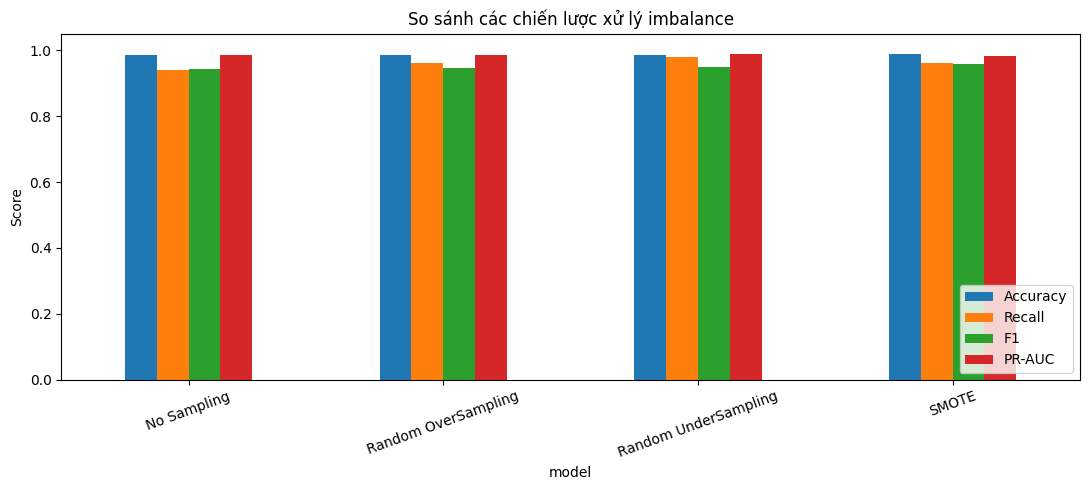

In [ ]:
plot_data = comparison_short[
    [
        "accuracy_mean",
        "recall_mean",
        "f1_mean",
        "pr_auc_mean"
    ]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("So sánh các chiến lược xử lý imbalance")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(
    ["Accuracy", "Recall", "F1", "PR-AUC"],
    loc="lower right"
)
plt.tight_layout()
plt.show()

Các phương pháp có Accuracy khá tương đồng, đều khoảng 98.5–98.8%. Vì vậy nếu chỉ nhìn Accuracy, rất khó nhận thấy sự khác biệt.

Sự khác biệt thể hiện rõ hơn ở Recall và F1:

Under-Sampling ưu tiên Recall.

No Sampling có Precision cao nhưng Recall thấp hơn.

SMOTE đạt sự cân bằng tốt nhất giữa Precision và Recall nên có F1 cao nhất.

Phân tích kết quả

Không có một kỹ thuật sampling luôn tốt nhất cho mọi bài toán.

Ví dụ:

- Over-sampling có thể làm Recall tăng nhưng Precision giảm.
- Under-sampling có thể làm mất thông tin của majority class.
- SMOTE có thể cải thiện minority class nhưng hiệu quả phụ thuộc cấu trúc dữ liệu.
- Không sampling đôi khi vẫn tốt nếu mô hình đã phân tách lớp tốt.

Điều quan trọng là **chọn metric phù hợp với mục tiêu của bài toán**.

# PHẦN 9. CHỌN MÔ HÌNH VÀ ĐÁNH GIÁ TRÊN TẬP TEST

## Bước 17. Chọn tiêu chí

Trong ví dụ này, ta minh họa việc chọn phương án có **F1 trung bình cao nhất trên Cross Validation**.

Có thể thay bằng:

- `recall_mean` nếu bỏ sót lớp dương là rất nghiêm trọng;
- `pr_auc_mean` nếu muốn đánh giá tốt hơn trong bối cảnh class imbalance;
- hoặc một tiêu chí nghiệp vụ riêng.

**Không chọn mô hình bằng kết quả trên tập test.**

In [ ]:
selection_metric = "f1_mean"

best_name = cv_comparison[selection_metric].idxmax()
best_model = models[best_name]

print("Tiêu chí lựa chọn:", selection_metric)
print("Pipeline được chọn:", best_name)
print(
    "CV score:",
    round(cv_comparison.loc[best_name, selection_metric], 4)
)

Tiêu chí lựa chọn: f1_mean
Pipeline được chọn: SMOTE
CV score: 0.9577


## Bước 18. Fit lại trên toàn bộ tập train

Sau khi đã chọn pipeline bằng CV, ta huấn luyện pipeline đó trên **toàn bộ tập train**.

In [ ]:
best_model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('sampler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'


## Bước 19. Đánh giá một lần trên tập test

Tập test đóng vai trò mô phỏng dữ liệu chưa từng thấy.

Ta tính:

- Accuracy;
- Precision;
- Recall;
- F1;
- ROC-AUC;
- PR-AUC.

In [ ]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR-AUC": average_precision_score(y_test, y_prob)
}, name="Test score")

display(test_metrics.round(4))

Accuracy     0.9762
Precision    0.9167
Recall       0.9167
F1           0.9167
ROC-AUC      0.9988
PR-AUC       0.9936
Name: Test score, dtype: float64

### Phân tích kết quả
Accuracy 97.62% cho thấy mô hình dự đoán đúng phần lớn các mẫu.

Recall = 91.67% có nghĩa mô hình phát hiện được khoảng 91.67% số mẫu Malignant trong test.

Precision = 91.67% có nghĩa trong các mẫu mà mô hình dự đoán là Malignant, khoảng 91.67% là đúng.

ROC-AUC và PR-AUC đều rất cao, cho thấy xác suất dự đoán của mô hình có khả năng phân tách hai lớp tốt.

## Bước 20. Confusion Matrix

Với quy ước:

- `0 = benign`
- `1 = malignant`

Confusion Matrix giúp ta phân tích:

- True Negative;
- False Positive;
- False Negative;
- True Positive.

Trong nhiều bài toán phát hiện rủi ro, **False Negative** là loại lỗi cần đặc biệt chú ý.

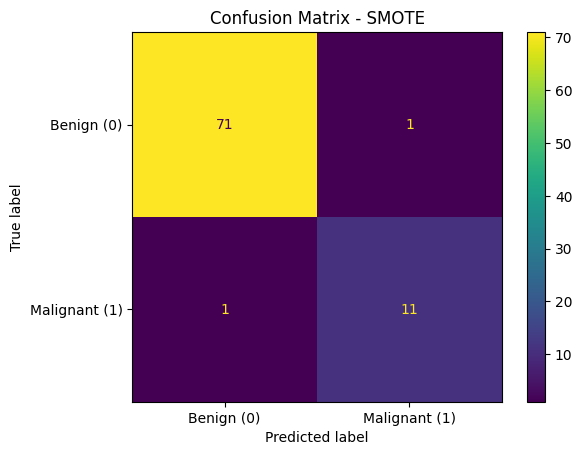

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Benign (0)", "Malignant (1)"]
)

plt.title(f"Confusion Matrix - {best_name}")
plt.show()

### Cách đọc

71 True Negative: Benign được dự đoán đúng.

1 False Positive: Benign bị dự đoán thành Malignant.

1 False Negative: Malignant bị dự đoán thành Benign.

11 True Positive: Malignant được phát hiện đúng.

## Bước 21. Classification Report

In [ ]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Benign (0)", "Malignant (1)"],
        digits=4,
        zero_division=0
    )
)

               precision    recall  f1-score   support

   Benign (0)     0.9861    0.9861    0.9861        72
Malignant (1)     0.9167    0.9167    0.9167        12

     accuracy                         0.9762        84
    macro avg     0.9514    0.9514    0.9514        84
 weighted avg     0.9762    0.9762    0.9762        84



### Cách đọc
Mỗi class có:

- precision

- recall

- f1-score

- support: số mẫu thật của class.

Ngoài ra cần chú ý:

- macro avg: trung bình hai class với trọng số bằng nhau.

- weighted avg: trung bình có trọng số theo số lượng mẫu từng class.

Với dữ liệu mất cân bằng, nên chú ý macro avg và metric của minority class thay vì chỉ nhìn weighted avg.

### Phân tích kết quả
Weighted F1 = 0.9762 khá cao vì dataset có nhiều Benign.

Trong khi đó Macro F1 = 0.9514, thấp hơn weighted average vì nó coi hai class quan trọng như nhau.

Với dữ liệu mất cân bằng, Macro Average thường phản ánh công bằng hơn hiệu năng giữa hai lớp

## Bước 22. Precision-Recall Curve

Khi positive class hiếm, Precision-Recall Curve thường hữu ích hơn việc chỉ nhìn Accuracy.

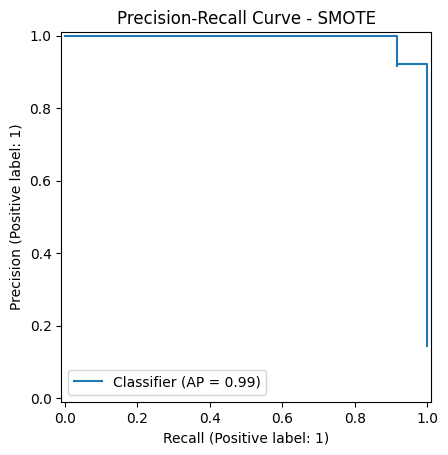

In [ ]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title(f"Precision-Recall Curve - {best_name}")
plt.show()

### Cách đọc
- Trục X: Recall.

- Trục Y: Precision.

Mỗi điểm trên đường cong tương ứng với một classification threshold khác nhau.

Một mô hình tốt có thể duy trì Precision cao trong khi Recall vẫn cao.

Diện tích/tóm tắt của Precision–Recall Curve được thể hiện bằng Average Precision hay PR-AUC.

### Phân tích kết quả
PR-AUC trên test đạt khoảng 0.9936, rất gần 1.

Điều này cho thấy mô hình duy trì Precision và Recall ở mức cao trên nhiều threshold khác nhau.

Lưu ý trong trường hợp class imbalance, PR-AUC cung cấp thông tin hữu ích hơn Accuracy đơn thuần về khả năng nhận diện minority class.

# PHẦN 10. PIPELINE CHUNG

Quy trình chuẩn trong bài này:

```text
1. Nạp dữ liệu
        ↓
2. Kiểm tra class distribution
        ↓
3. Tách X và y
        ↓
4. Train/Test Split với stratify=y
        ↓
5. Giữ nguyên tập test
        ↓
6. Xây Pipeline:
   StandardScaler
        ↓
   Sampling
        ↓
   Classifier
        ↓
7. Stratified K-Fold Cross Validation trên tập train
        ↓
8. So sánh Accuracy / Precision / Recall / F1 / ROC-AUC / PR-AUC
        ↓
9. Chọn phương án theo metric phù hợp
        ↓
10. Fit lại trên toàn bộ train
        ↓
11. Đánh giá một lần trên test
```

## Những lỗi cần tránh

### Lỗi 1. Chỉ nhìn Accuracy
Một mô hình luôn dự đoán majority class vẫn có thể có Accuracy cao.

### Lỗi 2. Chuẩn hóa trước khi chia dữ liệu
`StandardScaler.fit()` trên toàn bộ dataset gây leakage.

### Lỗi 3. Sampling trước Train/Test Split
Các mẫu được sao chép hoặc tạo mới có thể làm test không còn độc lập.

### Lỗi 4. Sampling validation/test
Sampling chỉ được áp dụng lên phần training.

### Lỗi 5. Sampling toàn bộ train trước Cross Validation
Sampling phải được thực hiện **bên trong từng fold**, tốt nhất bằng `imblearn.Pipeline`.

### Lỗi 6. Dùng KFold thông thường mà không để ý tỷ lệ lớp
Với dữ liệu imbalance, ưu tiên `StratifiedKFold`.

# PHẦN 11. BÀI TẬP THỰC HÀNH

### Bài 1 — Mức độ imbalance
Thay số mẫu malignant từ `60` thành:

- `40`;
- `120`;
- toàn bộ dữ liệu gốc.

So sánh Accuracy, Recall, F1 và PR-AUC.

---

### Bài 2 — KFold và StratifiedKFold
Dùng cùng Logistic Regression và so sánh:

- mean score;
- standard deviation giữa các fold.

Giải thích tại sao `StratifiedKFold` thường ổn định hơn với dữ liệu imbalance.

---

### Bài 3 — Thay đổi số fold
Lần lượt dùng:

- `K = 3`;
- `K = 5`;
- `K = 10`.

Quan sát sự thay đổi của mean và standard deviation.

---

### Bài 4 — Thay đổi mức Over-Sampling
Thử:

```python
RandomOverSampler(sampling_strategy=0.5)
RandomOverSampler(sampling_strategy=0.75)
RandomOverSampler(sampling_strategy=1.0)
```

Giải thích trade-off giữa Precision và Recall.

---

### Bài 5 — So sánh ba kỹ thuật sampling
So sánh:

- Random Over-Sampling;
- Random Under-Sampling;
- SMOTE.

Không chỉ chọn kỹ thuật có Accuracy cao nhất. Hãy giải thích bằng Precision, Recall, F1 và PR-AUC.

---

### Bài 6 — Thay classifier
Giữ nguyên quy trình preprocessing và sampling, thay Logistic Regression bằng:

- KNN;
- SVM;
- Decision Tree.

Phân tích mô hình nào nhạy với StandardScaler hơn.

---

### Bài 7 — Câu hỏi suy luận
Trả lời ngắn:

1. Tại sao không nên sampling tập test?
2. Tại sao không nên fit StandardScaler trên toàn bộ dữ liệu?
3. Khi nào Recall quan trọng hơn Precision?
4. Khi nào Precision quan trọng hơn Recall?
5. Vì sao PR-AUC thường hữu ích với dữ liệu imbalance?
6. Vì sao `StratifiedKFold` phù hợp hơn `KFold` trong bài này?
7. Random Under-Sampling có thể làm mất thông tin như thế nào?
8. SMOTE khác Random Over-Sampling ở điểm nào?

# LỜI GIẢI BÀI TẬP THỰC HÀNH - BUỔI 3

Phần này bổ sung đáp án diễn giải cho 7 bài tập cuối notebook. Các số liệu thực nghiệm tham chiếu trực tiếp từ các cell đã chạy của notebook: dữ liệu thực hành có 417 mẫu, gồm 357 benign (85,61%) và 60 malignant (14,39%).


## Bài 1. Thay đổi mức độ mất cân bằng

- Giảm malignant từ 60 xuống 40: minority class ít hơn, nên Recall/F1 và PR-AUC thường dao động mạnh hơn giữa các fold.
- Tăng lên 120 hoặc dùng đầy đủ dữ liệu gốc: mỗi fold có nhiều mẫu positive hơn, vì vậy ước lượng Recall, F1 và PR-AUC ổn định hơn.
- Accuracy không phản ánh đầy đủ chất lượng trong cả ba trường hợp; cần đọc cùng Recall, F1 và PR-AUC.


## Bài 2. KFold và StratifiedKFold

Nên dùng `StratifiedKFold` vì nó giữ tỷ lệ nhãn gần nhau trong từng fold. Kết quả notebook cho thấy KFold tạo tỷ lệ malignant validation từ 10,45% đến 17,91%, trong khi StratifiedKFold giữ khoảng 13,64% đến 14,93%. Vì vậy metric đánh giá của StratifiedKFold đáng tin cậy hơn với dữ liệu mất cân bằng.


## Bài 3. Thay đổi số fold

`K=3` nhanh hơn nhưng ít lần kiểm tra; `K=5` là lựa chọn cân bằng và được dùng trong notebook; `K=10` cho nhiều ước lượng hơn nhưng mỗi validation fold có ít positive hơn. Khi positive class ít, Recall có thể dao động lớn; do đó không nên chọn K quá lớn một cách máy móc.


## Bài 4. Mức Over-Sampling

Với `sampling_strategy=0.5` hoặc `0.75`, model thường tăng Recall mà chưa tạo quá nhiều false positive. Với `1.0`, hai lớp cân bằng hoàn toàn: Recall có thể tăng nhưng Precision có thể giảm. Chọn mức sampling theo hậu quả của false negative/false positive, không chỉ theo Accuracy.


## Bài 5. So sánh các kỹ thuật sampling

- Random Over-Sampling: không bỏ dữ liệu nhưng lặp lại minority samples.
- Random Under-Sampling: train nhanh và Recall cao, nhưng có thể mất thông tin majority.
- SMOTE: tạo mẫu minority tổng hợp từ lân cận.

Kết quả 5-fold CV: Under-Sampling có Recall cao nhất `0.9800`; SMOTE có F1 cao nhất `0.9577`, nên SMOTE được chọn cho test set.


## Bài 6. Thay classifier

KNN và SVM nhạy với thang đo do dùng khoảng cách; Logistic Regression cũng hưởng lợi từ StandardScaler do regularization. Decision Tree không nhạy với scale theo cùng cách vì tách tại ngưỡng từng feature. Với KNN/SVM, phải đặt scaler và sampler trong pipeline để tránh data leakage.


## Bài 7. Câu hỏi suy luận

Không sampling test set vì test phải đại diện dữ liệu chưa thấy. Không fit scaler trên toàn bộ dữ liệu vì sẽ rò rỉ thông tin test vào train. Recall quan trọng khi bỏ sót positive nguy hiểm; Precision quan trọng khi false positive tốn kém. PR-AUC hữu ích trong imbalance vì tập trung vào positive class. StratifiedKFold ổn định tỷ lệ lớp. Under-Sampling có thể bỏ mất mẫu majority hữu ích; SMOTE sinh mẫu tổng hợp còn Over-Sampling sao chép mẫu minority.


## Kết quả được chọn

Pipeline `StandardScaler -> SMOTE -> LogisticRegression` đạt F1 CV `0.9577`. Trên test: Accuracy `0.9762`, Precision `0.9167`, Recall `0.9167`, F1 `0.9167`, ROC-AUC `0.9988`, PR-AUC `0.9936`. Confusion matrix: TN=71, FP=1, FN=1, TP=11.
